In [13]:
import base64
import io
import json
import os
from hashlib import md5

import open_clip
import torch
from PIL import Image
from matplotlib import pyplot as plt
from torch.utils.data.dataloader import DataLoader

In [14]:
class ClipModel(torch.nn.Module):
    def __init__(self, model_name="ViT-B-32", pretrained="laion2b_s34b_b79k"):
        super().__init__()
        self.clip_backbone, _, self.preprocess = open_clip.create_model_and_transforms(model_name=model_name,
                                                                                       pretrained=pretrained)
        for p in self.clip_backbone.parameters():
            p.requires_grad = False
        self.clip_backbone.eval()
        self.tokenizer = open_clip.get_tokenizer('ViT-B-32')

        self.class_labels = ["class1", "class2", "class3", "class4"]
        self.class_tokens = self.tokenizer(self.class_labels)
        self.class_features = self.clip_backbone.encode_text(self.class_tokens)
        if torch.cuda.is_available():
            self.class_features /= self.class_features.norm(dim=-1, keepdim=True)
            self.class_features = self.class_features.cuda()

        self.head = torch.nn.Linear(self.clip_backbone.visual.output_dim,
                                    self.clip_backbone.visual.output_dim)
        if torch.cuda.is_available():
            self.clip_backbone.cuda()
            self.head.cuda()

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        with torch.no_grad():
            image_features = self.clip_backbone.encode_image(images)
        image_features = self.head(image_features)
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        class_similarity = (100.0 * image_features @ self.class_features.T).softmax(dim=-1)
        return class_similarity


In [15]:
class ApiResponsesDataset(torch.utils.data.Dataset):
    def __init__(self, clip_preprocess, img_dir="../img", responses_cache="../cache/responses.json"):
        super().__init__()
        self.clip_preprocess = clip_preprocess
        self.img_dir = img_dir
        self.responses_cache = responses_cache

        self.responses_json = json.load(open(responses_cache, "r"))
        self.raw_images = [Image.open(f"{img_dir}/{p}") for p in os.listdir(img_dir)]

        self.data = []
        self.labels = []

        self.preprocess()

    def preprocess(self):
        self.data = [self.clip_preprocess(raw_img) for raw_img in self.raw_images]

        try:
            for raw_img in self.raw_images:
                buf = io.BytesIO()
                raw_img.save(buf, format="PNG")
                img_base64_bytes = base64.b64encode(buf.getvalue())
                img_hash = md5(img_base64_bytes).hexdigest()
                response = self.responses_json[img_hash]
                label = torch.Tensor([value for value in response['classes'].values()])
                self.labels.append(label)
        except KeyError:
            exit(f"Dataset integrity error. Not all images have responses.")

    def __len__(self):
        return len(self.raw_images)

    def __getitem__(self, index):
        return self.data[index], self.labels[index]

In [16]:
# TODO Add validation
def train_model(model, optimizer, criterion, train_data, num_epochs):
    losses = []
    for epoch in range(num_epochs):
        print(f"Epoch {epoch + 1}/{num_epochs}")
        epoch_loss = 0.0
        for data, labels in train_data:
            if torch.cuda.is_available():
                data = data.cuda()
                labels = labels.cuda()
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        losses.append(epoch_loss / len(train_data))
        print(f"Train loss: {losses[-1]}")

    plt.plot(losses)
    plt.title("Loss curve")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.show()

    return model



Epoch 1/10
Train loss: 2.802663469314575
Epoch 2/10
Train loss: 2.701438140869141
Epoch 3/10
Train loss: 2.6587029933929442
Epoch 4/10
Train loss: 2.620992565155029
Epoch 5/10
Train loss: 2.592396116256714
Epoch 6/10
Train loss: 2.568320369720459
Epoch 7/10
Train loss: 2.5455727577209473
Epoch 8/10
Train loss: 2.5369255542755127
Epoch 9/10
Train loss: 2.5308894157409667
Epoch 10/10
Train loss: 2.5277500629425047


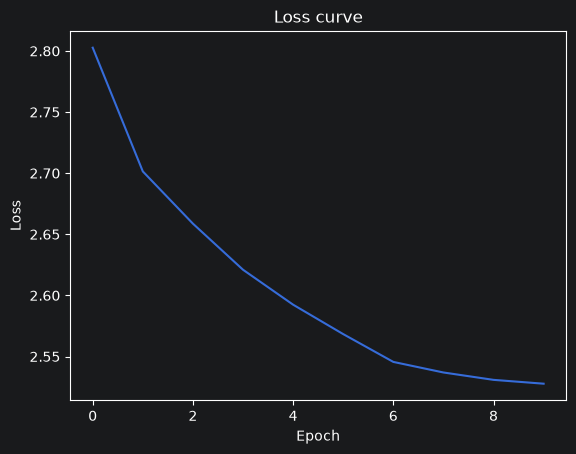

In [18]:
WEIGHTS_DIR = "../weights"
RANDOM_SEED = 161
BATCH_SIZE = 1
LEARNING_RATE = 1e-4
NUM_EPOCHS = 10

torch.random.manual_seed(RANDOM_SEED)

clip_model = ClipModel()

dataset = ApiResponsesDataset(clip_model.preprocess)
train_dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

adam_optimizer = torch.optim.Adam(clip_model.head.parameters(), lr=LEARNING_RATE)

crossEntropyLoss = torch.nn.CrossEntropyLoss()

trained_model = train_model(model=clip_model,
                optimizer=adam_optimizer,
                criterion=crossEntropyLoss,
                train_data=train_dataloader,
                num_epochs=NUM_EPOCHS)

torch.save(trained_model.head.state_dict(), f"{WEIGHTS_DIR}/classifier_head.pth")
